# Project 1: Financial & E-Commerce Fraud Early Detection Analysis

### **Theme:** Financial Crime, Fintech Risk & Real-Time Fraud Prevention
### **Key Focus:** Anomaly Detection, Velocity Checks, Geospatial "Impossible Travel", Class Imbalance, False-Positive Optimization

---

## 📖 Notebook Overview & Project Structure
This notebook contains an end-to-end Machine Learning pipeline optimized to address severe class imbalance and perform early-stage fraud risk scoring on financial transaction databases.

### **1. Database Verification & Exploration** (`_Tszb5UYMcfL`)
* Connects to SQLite database `fraud_detection.db`.
* Inspects schema, retrieves tables, and previews transaction records.

### **2. Setup & Data Loading** (`aZnfuMpmMop8`, `mBhy3WEcmIcA`)
* Installs dependencies: `scikit-learn`, `xgboost`, `imbalanced-learn`.
* Loads pre-processed training (`v_ml_train`) and test (`v_ml_test`) datasets from `fraud_detection_hypertuned.db`.
* Splits independent features ($X$) and target classes ($y$), separating key metadata like `transaction_id`.

### **3. Class Imbalance Strategies** (`zKNCcmpkMLaK`)
* **SMOTE (Synthetic Minority Over-sampling Technique):** Balances minority fraud instances dynamically for scikit-learn tree estimators.
* **Scale Position Weights:** Calculates positive class weighting ratios to directly adjust loss functions in XGBoost.

### **4. Hyperparameter Optimization** (`BFXMploFPJIY`)
* **Model 1: Gradient Boosting Classifier:** Wrapped in an Imbalanced-Learn pipeline containing SMOTE + stratified cross-validation.
* **Model 2: XGBoost Classifier:** Evaluated via randomized search focused heavily on optimizing PR-AUC (Precision-Recall Area Under Curve).

### **5. Model Validation & Evaluation** (`z0RWioqDvHnf`)
* Builds a baseline `StandardScaler` + balanced `LogisticRegression` pipeline.
* Generates probabilistic predictions for each classifier, blending them into a high-performing soft voting **Ensemble (GB + XGB)**.
* Evaluates model calibration and fraud targeting performance using PR-AUC, F1-Score, Brier Score, and Fraud-specific MAPE.

### **6. Visual Analytics & Deliverables** (`aIFm9RWgyuTf`)
* Plots comparison Precision-Recall Curves and builds Confusion Matrices to assess operational trade-offs.
* Maps ensemble probabilities into risk categories: *Low, Medium, High, Extreme Risk* tiers.
* Exports final risk-scored test records to `scored_test_predictions.csv`.

In [19]:
#installing scikit-learn xgboost and imbalanced-learn
!pip install -q scikit-learn xgboost imbalanced-learn pandas numpy matplotlib seaborn

from google.colab import files
uploaded = files.upload()

Saving fraud_detection_hypertuned.db to fraud_detection_hypertuned (1).db


In [20]:

import sqlite3
import numpy as np
import pandas as pd

#connect
conn = sqlite3.connect("fraud_detection_hypertuned.db")

#train and test df
train_df = pd.read_sql_query("SELECT * FROM v_ml_train", conn)
test_df = pd.read_sql_query("SELECT * FROM v_ml_test", conn)

conn.close()

#separating
drop_cols = ['is_fraud', 'transaction_id']
x_train = train_df.drop(columns=drop_cols)
y_train = train_df['is_fraud']

x_test = test_df.drop(columns=drop_cols)
y_test = test_df['is_fraud']

print(f"Train shape: {x_train.shape} | Fraud rate: {y_train.mean()*100:.2f}%")
print(f"Test shape: {x_test.shape} | Fraud rate: {y_test.mean()*100:.2f}%")


Train shape: (8000, 49) | Fraud rate: 3.33%
Test shape: (2000, 49) | Fraud rate: 3.35%


In [21]:
#Gradient Boost

#SMOTE-balance training set for Gradient Boosting
from imblearn.over_sampling import SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(x_train, y_train)
print(f"After SMOTE: {X_train_smote.shape} | Fraud count: {y_train_smote.sum()}")

#Imbalance Ratio for XGBoost
imbalance_ratio = (y_train_smote == 0 ).sum() / (y_train == 1).sum()
print(f"XGBoost scale_post_weight: {imbalance_ratio:.2f}")

After SMOTE: (15468, 49) | Fraud count: 7734
XGBoost scale_post_weight: 29.08


In [22]:
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import xgboost as xgb

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Model 1: SciKit-Learn GradientBoostingClassifier

gb_pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_param_dist = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [3, 4, 5, 6],
    "classifier__subsample": [0.7, 0.8, 1.0],
    "classifier__min_samples_leaf": [1, 3, 5],
}

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=gb_param_dist,
    n_iter=12,
    scoring='average_precision',
    n_jobs=-1,
    cv=cv,
    verbose=1,
    random_state=42
)

gb_search.fit(x_train, y_train)
print("Best Gradient Boosting Params:", gb_search.best_params_)
print(f"Best Gradient Boosting CV PR-AUC: {gb_search.best_score_:.4f}")

#Model 2: XGBoost Classifier

xgb_base = xgb.XGBClassifier(
    scale_pos_weight=imbalance_ratio,
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1,
)

xgb_param_dist = {
    "n_estimators": [200, 300, 400],
    "learning_rate": [0.03, 0.05, 0.1],
    "max_depth": [4, 5, 6, 8],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.7, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1.0],
    "reg_lambda": [1.0, 2.0, 5.0],
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=xgb_param_dist,
    n_iter=15,
    scoring='average_precision',
    n_jobs=-1,
    cv=cv,
    verbose=1,
    random_state=42
)

xgb_search.fit(x_train, y_train)
print("Best XGBoost Params:", xgb_search.best_params_)
print(f"Best XGBoost CV PR-AUC: {xgb_search.best_score_:.4f}")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Gradient Boosting Params: {'classifier__subsample': 1.0, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 5, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.1}
Best Gradient Boosting CV PR-AUC: 0.9973
Fitting 5 folds for each of 15 candidates, totalling 75 fits
Best XGBoost Params: {'subsample': 1.0, 'reg_lambda': 1.0, 'reg_alpha': 0, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best XGBoost CV PR-AUC: 0.9985


In [23]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    r2_score,
    mean_absolute_error,
    brier_score_loss,
)
import numpy as np
import pandas as pd

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
)

baseline.fit(x_train, y_train)

best_gb = gb_search.best_estimator_
best_xgb = xgb_search.best_estimator_

def evaluate_probs(name, y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    fraud_mask = (y_true.values == 1)
    mape_fraud = np.mean(np.abs(y_true.values[fraud_mask] - y_proba[fraud_mask])) * 100.0
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1": f1_score(y_true, y_pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "R2 (Proba)" : r2_score(y_true, y_proba),
        "MAPE (y=1)%" : mape_fraud,
        "MAE": mean_absolute_error(y_true, y_proba),
        "Brier": brier_score_loss(y_true, y_proba),
    }

proba_base = baseline.predict_proba(x_test)[:, 1]
proba_gb = best_gb.predict_proba(x_test)[:, 1]
proba_xgb = best_xgb.predict_proba(x_test)[:, 1]
proba_ens = 0.5 * proba_gb + 0.5 * proba_xgb

results_df = pd.DataFrame([
    evaluate_probs("Logistic Regression", y_test, proba_base),
    evaluate_probs("Gradient Boosting", y_test, proba_gb),
    evaluate_probs("XGBoost", y_test, proba_xgb),
    evaluate_probs("Ensemble (GB+XGB)", y_test, proba_ens),
]).set_index("Model").round(4)

display(results_df.sort_values("PR-AUC", ascending=False))

,Accuracy,Precision,Recall,F1,ROC_AUC,PR-AUC,R2 (Proba),MAPE (y=1)%,MAE,Brier
Model,,,,,,,,,,
Gradient Boosting,0.9975,0.9844,0.9403,0.9618,0.9999,0.9985,0.9390,5.7066,0.0023,0.0020
Ensemble (GB+XGB),0.9980,0.9846,0.9552,0.9697,0.9999,0.9977,0.9562,4.4842,0.0021,0.0014
Logistic Regression,0.9970,0.9296,0.9851,0.9565,0.9999,0.9964,0.9326,1.3975,0.0036,0.0022
XGBoost,0.9985,0.9848,0.9701,0.9774,0.9997,0.9948,0.9621,3.2619,0.0018,0.0012


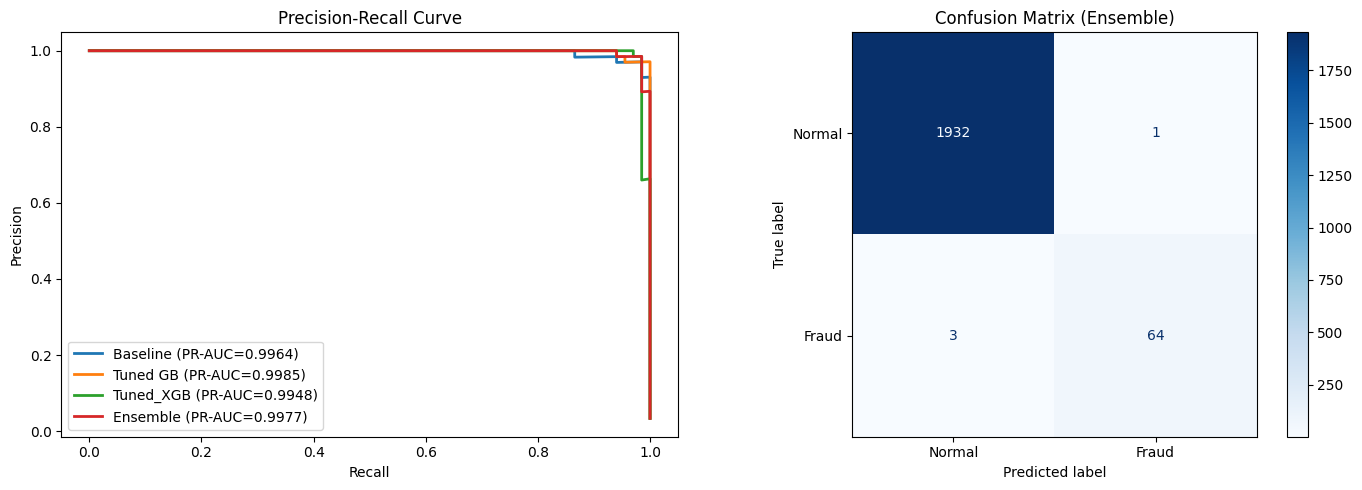

Predictions saved to scored_test_predictions.csv


In [24]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, ConfusionMatrixDisplay, average_precision_score
import numpy as np
import pandas as pd

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

#1. Precision-Recall Curves
for label, probs in [("Baseline", proba_base), ("Tuned GB", proba_gb),
                     ("Tuned_XGB", proba_xgb), ("Ensemble", proba_ens)]:
    p, r, _ = precision_recall_curve(y_test, probs)
    ap = average_precision_score(y_test, probs)
    axes[0].plot(r, p, linewidth=2, label=f"{label} (PR-AUC={ap:.4f})")

axes[0].set_title("Precision-Recall Curve")
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].legend()

#2 Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    (proba_ens >= 0.5).astype(int),
    display_labels=["Normal", "Fraud"],
    cmap="Blues",
    ax=axes[1]
)
axes[1].set_title("Confusion Matrix (Ensemble)")
plt.tight_layout()
plt.show()

out = test_df[["transaction_id", "transaction_amount", "is_fraud"]].copy()
out["fraud_probability"] = np.round(proba_ens, 4)
out["risk_tier"] = pd.cut(
    out["fraud_probability"],
    bins=[-0.01, 0.40, 0.6, 0.85, 1.01],
    labels=["Low Risk", "Medium Risk", "High Risk", "Extreme Risk"]
)
out.to_csv("scored_test_predictions.csv", index=False)
print("Predictions saved to scored_test_predictions.csv")